# Example of the aitlas toolbox in the context of semantic segmentation

## Import the required packages

In [ ]:
from aitlas.datasets import ArcticSeaIceImageMaskingDataset
from aitlas.utils import image_loader
from aitlas.models import DeepLabV3
from aitlas.transforms import MinMaxNormTranspose
import csv
import matplotlib.pyplot as plt 

## Visualize images and masks

Total number of patches: 2714


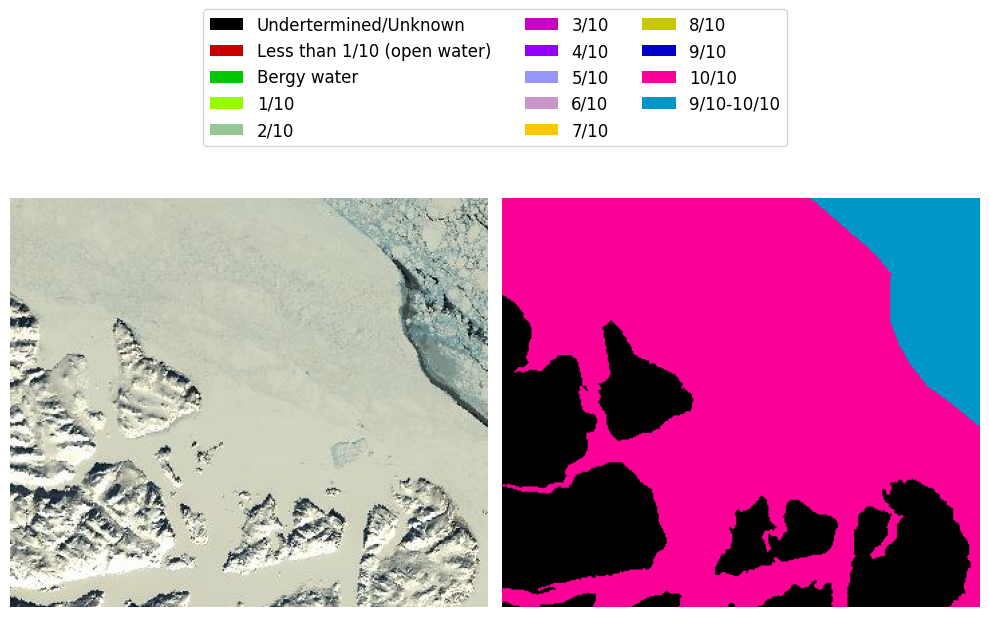

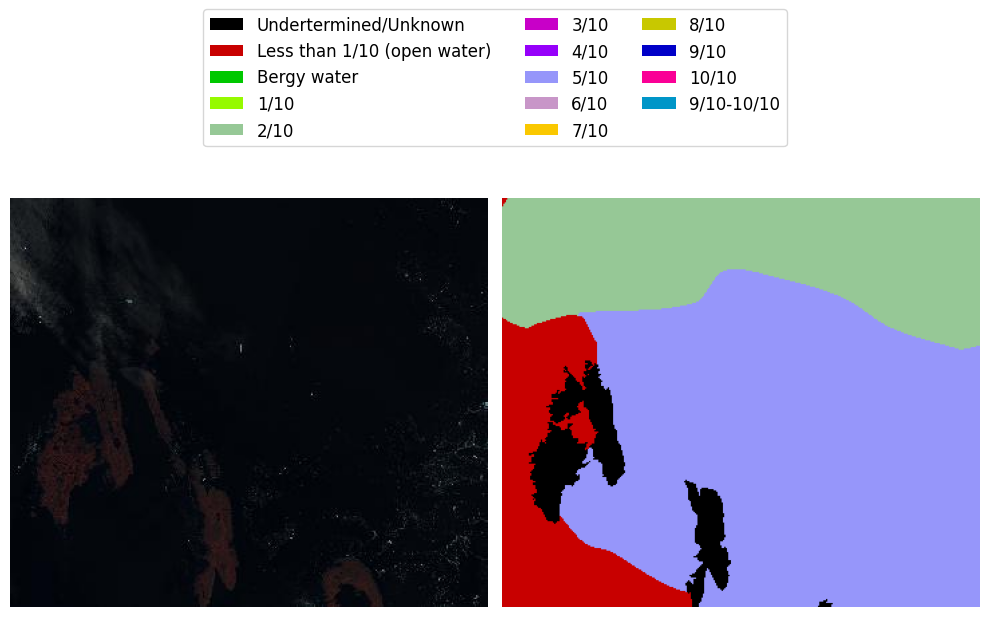

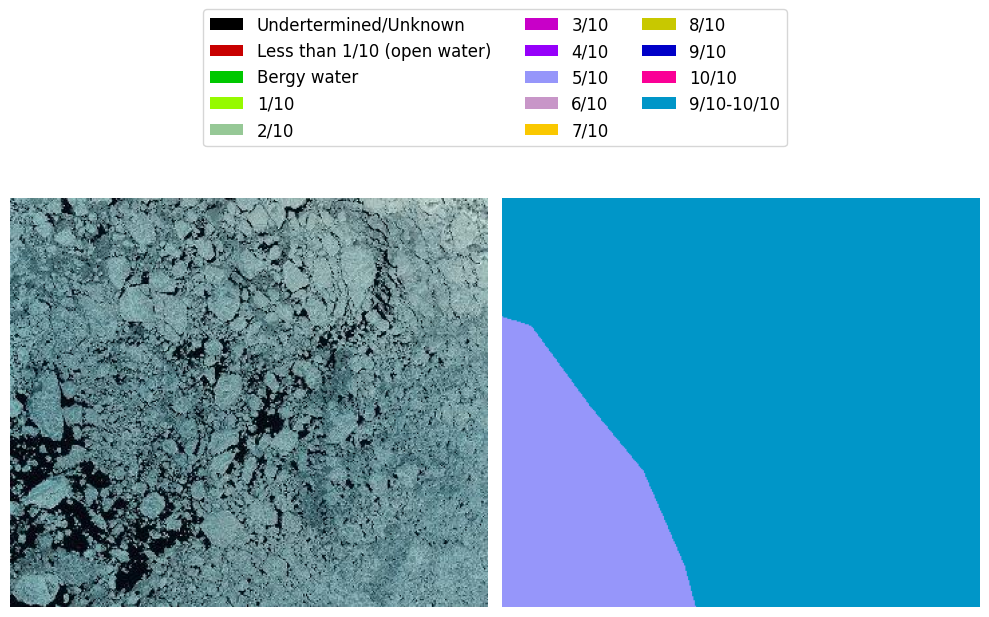

In [4]:
dataset_config = {
    "data_dir": "/home/dragik/data/FAIR_EO/arctic_sea_ice_image_masking/",
    "csv_file": "/home/dragik/data/FAIR_EO/arctic_sea_ice_image_masking/train.csv"
}
dataset = ArcticSeaIceImageMaskingDataset(dataset_config)

print(f"Total number of patches: {len(dataset)}")
dataset.show_image(1);
dataset.show_image(300);
dataset.show_image(1500);

In [5]:
dataset.data_distribution_table()

,Number of pixels
Undertermined/Unknown,73930464.0
Less than 1/10 (open water),20914520.0
Bergy water,11530111.0
1/10,225981.0
2/10,8020844.0
3/10,1561226.0
4/10,71465.0
5/10,7175439.0
6/10,36119.0
7/10,5014915.0


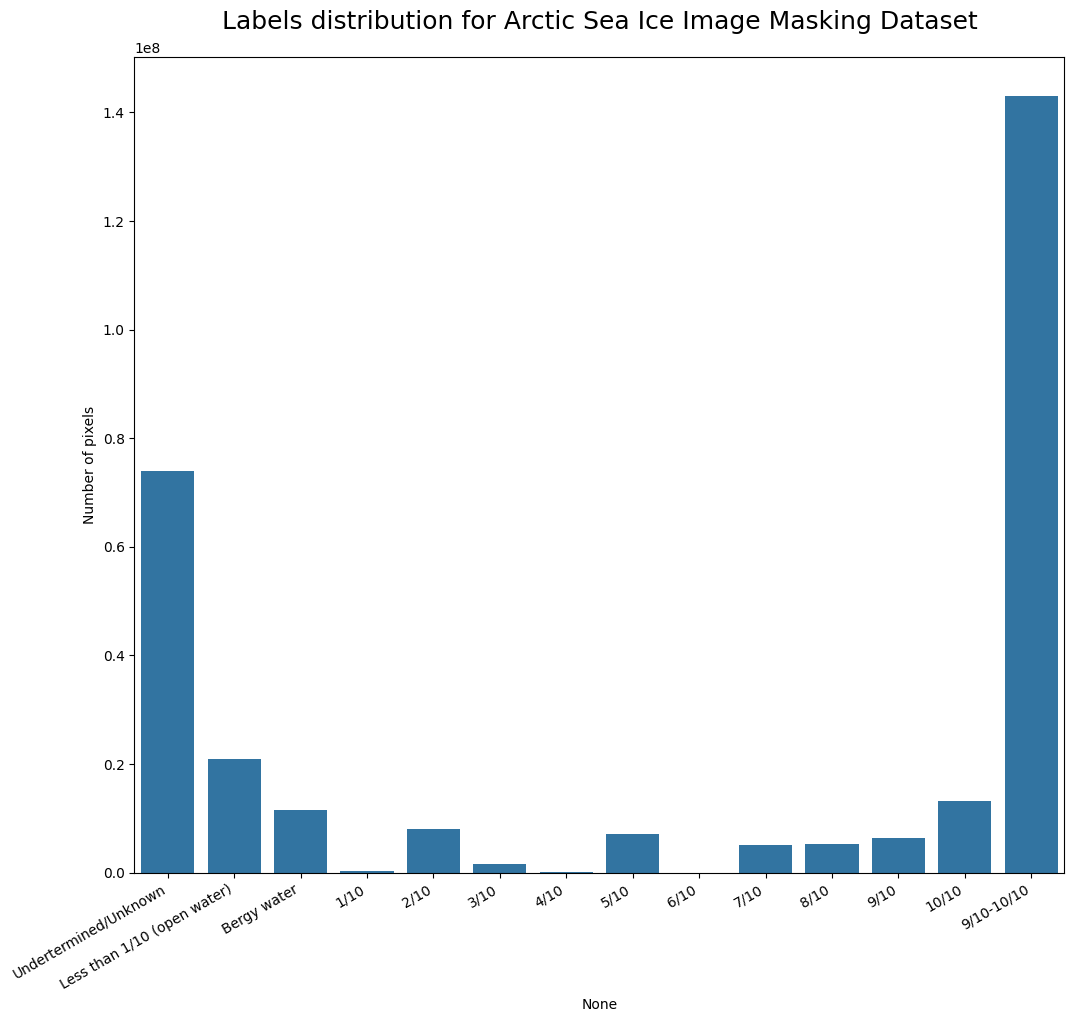

In [6]:
dataset.data_distribution_barchart();

## Load training data

In [4]:
train_dataset_config = {
    "batch_size": 8,
    "shuffle": True,
    "num_workers": 4,
    "data_dir": "/home/dragik/data/FAIR_EO/arctic_sea_ice_image_masking/",
    "csv_file": "/home/dragik/data/FAIR_EO/arctic_sea_ice_image_masking/train.csv",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"], 
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"] 
}
train_dataset = ArcticSeaIceImageMaskingDataset(train_dataset_config)
len(train_dataset)

2714

## Create the model

In [5]:
epochs = 10
model_directory = "/home/dragik/data/FAIR_EO/arctic_sea_ice_image_masking"
model_config = {
    "num_classes": 14, 
    "learning_rate": 0.0001,
    "pretrained": True, 
    "threshold": 0.5,
    "metrics": ["iou"]
}

model = DeepLabV3(model_config)
model.prepare()

## Start the training

In [9]:
model.train_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    run_id='1'
);

2025-05-29 14:04:44,405 INFO Starting training.
training: 100%|██████████| 340/340 [24:53<00:00,  4.39s/it]
2025-05-29 14:29:38,353 INFO epoch: 1, time: 1494, loss:  0.68508
testing on train set: 100%|██████████| 340/340 [24:31<00:00,  4.33s/it]
2025-05-29 14:54:12,265 INFO IOU:0.5728104409788143, IOU mean:0.169893500067286, IOU per Class:[0.65713813 0.38144765 0.21970373 0.         0.         0.
 0.         0.         0.         0.         0.         0.
 0.30078853 0.81943096]
training: 100%|██████████| 340/340 [23:53<00:00,  4.22s/it]
2025-05-29 15:18:06,137 INFO epoch: 2, time: 1434, loss:  0.39243
testing on train set: 100%|██████████| 340/340 [22:24<00:00,  3.95s/it]
2025-05-29 15:40:30,622 INFO IOU:0.5956083370118902, IOU mean:0.15618962285412571, IOU per Class:[0.59207396 0.42686954 0.         0.         0.         0.
 0.         0.         0.         0.         0.         0.
 0.32851901 0.83919221]
training: 100%|██████████| 340/340 [22:24<00:00,  3.95s/it]
2025-05-29 16:02:55,

## Evaluate the model

In [10]:
test_dataset_config = {
    "batch_size": 4,
    "shuffle": False,
    "num_workers": 4,
    "data_dir": "/home/dragik/data/FAIR_EO/arctic_sea_ice_image_masking/",
    "csv_file": "/home/dragik/data/FAIR_EO/arctic_sea_ice_image_masking/val.csv",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"], 
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"] 
}

test_dataset = ArcticSeaIceImageMaskingDataset(test_dataset_config)
print(len(test_dataset))

model = DeepLabV3(model_config)
model.prepare()
model.running_metrics.reset()
model_path = "/home/dragik/data/FAIR_EO/arctic_sea_ice_image_masking/checkpoint.pth.tar"
model.evaluate(dataset=test_dataset, model_path=model_path)
model.running_metrics.get_scores(model.metrics)

339


2025-05-30 06:34:13,017 INFO Loading checkpoint /home/dragik/data/FAIR_EO/arctic_sea_ice_image_masking/checkpoint.pth.tar
2025-05-30 06:34:14,204 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/arctic_sea_ice_image_masking/checkpoint.pth.tar at epoch 11
testing on test set: 100%|██████████| 85/85 [02:50<00:00,  2.01s/it]


[{'IOU': 0.6837572758395621,
  'IOU mean': 0.19100841557969447,
  'IOU per Class': array([0.76522844, 0.43352403, 0.        , 0.        , 0.        ,
         0.        , 0.        , 0.        , 0.        , 0.        ,
         0.        , 0.        , 0.58106356, 0.89430179])}]

## Predictions

2025-05-30 06:45:54,664 INFO Loading checkpoint /home/dragik/data/FAIR_EO/arctic_sea_ice_image_masking/checkpoint.pth.tar
2025-05-30 06:45:55,906 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/arctic_sea_ice_image_masking/checkpoint.pth.tar at epoch 11


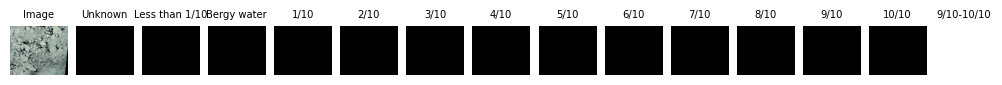

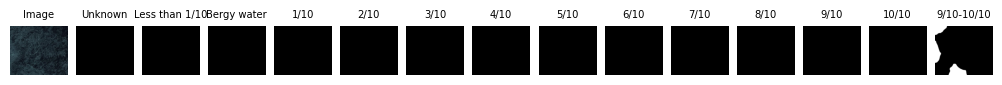

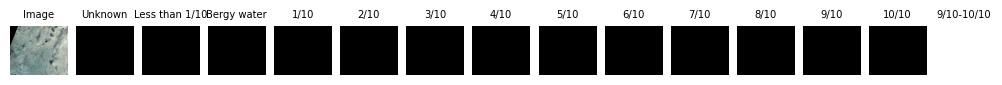

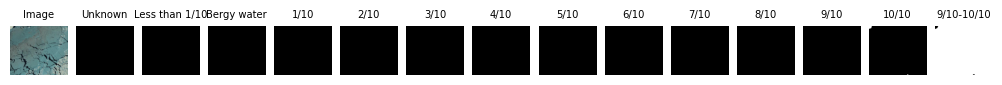

In [8]:
model_path = "/home/dragik/data/FAIR_EO/arctic_sea_ice_image_masking/checkpoint.pth.tar"
labels = ["Unknown","Less than 1/10","Bergy water","1/10","2/10","3/10","4/10","5/10","6/10","7/10","8/10","9/10","10/10","9/10-10/10"]
transform = MinMaxNormTranspose()
model.load_model(model_path)
plt.rcParams.update({'font.size': 6})
csv_file = "/home/dragik/data/FAIR_EO/arctic_sea_ice_image_masking/test.csv"

test_list = []
with open(csv_file, mode ='r')as file:
    csvFile = csv.reader(file)
    for lines in csvFile:
        test_list.append(lines[0])

image = image_loader('/home/dragik/data/FAIR_EO/arctic_sea_ice_image_masking/' + test_list[0])
fig = model.predict_masks(image, labels, transform)

image = image_loader('/home/dragik/data/FAIR_EO/arctic_sea_ice_image_masking/' + test_list[1])
fig = model.predict_masks(image, labels, transform)

image = image_loader('/home/dragik/data/FAIR_EO/arctic_sea_ice_image_masking/' + test_list[10])
fig = model.predict_masks(image, labels, transform)

image = image_loader('/home/dragik/data/FAIR_EO/arctic_sea_ice_image_masking/' + test_list[50])
fig = model.predict_masks(image, labels, transform)